# 09 - Circuit diagrams of the kernels (week 3)
Owner: **Haider**

Professor's feedback on week 2: *add circuit diagrams to show the architectures of the kernels used.* This notebook draws every circuit straight from the code in `src/`, so the pictures are exactly the circuits that produced our results. Nothing is re-run and no quantum time is used.

1. **Encoding circuit** $U(x)$: [$R_y(\alpha x_i)$ on every qubit + CNOT chain] $\times L$, with $L=2$ (`common.encoding_circuit`).
2. **Fidelity kernel**: compute-uncompute circuit $U(x')^\dagger U(x)$; $k(x,x')$ = probability of the all-zero outcome. **One circuit per pair** of images (`fidelity.overlap_circuit`).
3. **Projected kernel**: $U(x)$ followed by a basis change and measurement of all qubits, in the $Z$, $X$ ($H$) and $Y$ ($S^\dagger H$) bases. **Three circuits per image**, giving every qubit's 1-RDM (`projected._basis_circuit`).
4. **What the hardware runs**: the projected $Z$-basis circuit after transpilation to `ibm_kingston` (native gates $R_z$, $\sqrt{X}$, $X$, $CZ$; physical qubits 0-5).

Diagrams 1-3 use $n=4$ qubits so they stay readable; the structure is the same for $n=2,\dots,8$. Diagram 4 uses $n=6$, the hardware setting.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit.circuit.library import unitary_overlap
from qiskit_ibm_runtime.fake_provider import FakeKingston
from src.common import encoding_circuit, RESULTS
from src.projected import _basis_circuit, BASES
from src.hardware import transpile_for
from src.noise import noisy_resources

try:
    import pylatexenc                     # needed by Qiskit's matplotlib circuit drawer
except ImportError:
    raise ImportError("run  pip install pylatexenc  in the .venv terminal, then restart the kernel")

figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)
N_DRAW, N_HW, LAYERS = 4, 6, 2

def save(fig, name):
    fig.savefig(figdir / name, dpi=200, bbox_inches="tight")
    plt.show()
    print("saved", name)

## 1. Encoding circuit $U(x)$ ($n=4$, $L=2$)
Parameters `x[i]` are the rotation angles $\alpha x_i$ (PCA feature $i$, scaled to $[-1,1]$, times $\alpha$). The CNOT chain entangles neighbouring qubits; with $L=1$ the CNOTs cancel in the fidelity kernel ($U(x')^\dagger U(x)$), so $L=2$ is our main setting.

In [2]:
enc = encoding_circuit(N_DRAW, LAYERS)
print(f"n={N_DRAW}, L={LAYERS}: {enc.count_ops()}, depth {enc.depth()}")
fig = enc.draw("mpl", fold=-1)
save(fig, "circuit_encoding.png")

n=4, L=2: OrderedDict({'ry': 8, 'cx': 6}), depth 7
saved circuit_encoding.png


## 2. Fidelity kernel: compute-uncompute circuit
$U(x)$ (parameters `x`) followed by $U(x')^\dagger$ (parameters `x'`), then measure all qubits: $k(x,x') = |\langle\psi(x')|\psi(x)\rangle|^2 = P(00\dots0)$. Our code builds this with Qiskit's `unitary_overlap` (`src/fidelity.py`); for a readable drawing we compose the same two blocks by hand and check they are the same unitary.

In [3]:
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Operator
xp = ParameterVector("x'", N_DRAW)
U_x = enc.copy()
U_xp_dag = enc.assign_parameters(list(xp)).inverse()
ov = U_x.copy()
ov.barrier(label="U(x)  |  U(x')†")
ov.compose(U_xp_dag, inplace=True)
ov.measure_all()

# check: same unitary as unitary_overlap (the circuit our code runs), random angles
rng = np.random.default_rng(0)
a, b = rng.uniform(-np.pi, np.pi, (2, N_DRAW))
ref = unitary_overlap(enc.assign_parameters(a), enc.assign_parameters(b))
mine = U_x.assign_parameters(a).compose(enc.assign_parameters(b).inverse())
print("same unitary as unitary_overlap:", Operator(ref).equiv(Operator(mine)))
print(f"overlap circuit: {dict(ov.count_ops())}, depth {ov.depth()}")
fig = ov.draw("mpl", fold=-1)
save(fig, "circuit_fidelity.png")

same unitary as unitary_overlap: True
overlap circuit: {'ry': 16, 'cx': 12, 'measure': 4, 'barrier': 2}, depth 15
saved circuit_fidelity.png


## 3. Projected kernel: three measurement circuits per image
Same $U(x)$, then a basis change on every qubit before measuring all of them:
$Z$ basis: nothing; $X$ basis: $H$; $Y$ basis: $S^\dagger$ then $H$. From the counts we get $\langle X_k\rangle, \langle Y_k\rangle, \langle Z_k\rangle$ for every qubit $k$ at once, hence the 1-RDM $\rho_k(x)$ and the kernel $k(x,x') = \exp\!\big(-\gamma\sum_k \|\rho_k(x)-\rho_k(x')\|_F^2\big)$. Built with `projected._basis_circuit`, the function used for all sampled, noisy and hardware runs.

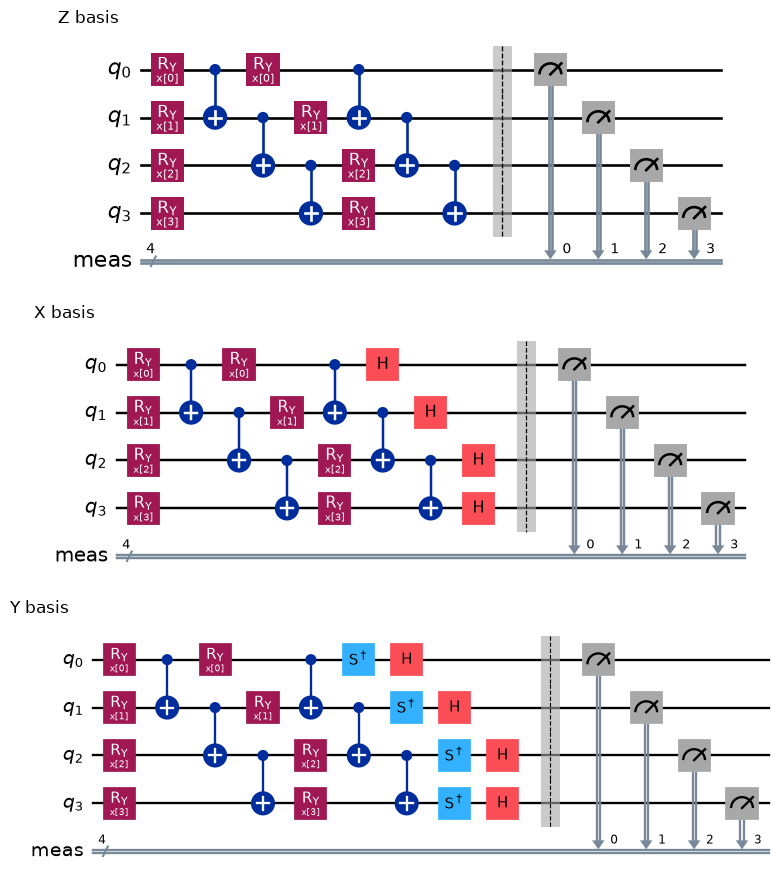

saved circuit_projected.png


In [4]:
params = list(enc.parameters)                  # keep the symbols x[i] in the drawing
basis_circs = {b: _basis_circuit(enc, params, b) for b in ("Z", "X", "Y")}
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (b, qc) in zip(axes, basis_circs.items()):
    qc.draw("mpl", fold=-1, ax=ax)
    ax.set_title(f"{b} basis", fontsize=12, loc="left")
fig.tight_layout()
save(fig, "circuit_projected.png")

## 4. What the hardware runs: projected $Z$-basis circuit on `ibm_kingston` ($n=6$)
Transpiled exactly as in notebooks 06 and 07 (optimisation level 1, fixed transpiler seed, physical qubits 0-5). Generic angles 0.5 are used so no gate is optimised away. Every $R_y$ becomes $R_z$/$\sqrt{X}$ gates and every CNOT becomes a $CZ$ with single-qubit gates around it. Idle qubits of the 156-qubit device are hidden.

In [5]:
fake = FakeKingston()
enc6 = encoding_circuit(N_HW, LAYERS)
qz = _basis_circuit(enc6, np.full(N_HW, 0.5), "Z")
tz = transpile_for(fake, [qz], N_HW)[0]
ops = tz.count_ops()
print(f"transpiled: depth {tz.depth()}, {ops.get('cz', 0)} CZ, gates {dict(ops)}, "
      f"physical qubits {list(tz.layout.final_index_layout())}")
fig = tz.draw("mpl", fold=-1, idle_wires=False)
save(fig, "circuit_projected_transpiled_kingston.png")

transpiled: depth 33, 10 CZ, gates {'rz': 33, 'sx': 33, 'cz': 10, 'measure': 6, 'barrier': 1}, physical qubits [0, 1, 2, 3, 4, 5]
saved circuit_projected_transpiled_kingston.png


## 5. Cost summary of the two kernel architectures (transpiled to `ibm_kingston`)
Per-image vs per-pair cost is the reason only the projected kernel could run on hardware (80 training + 40 test images).

In [6]:
n_tr, n_te = 80, 40
print(f"{'n':>3}{'proj depth':>12}{'proj CZ':>9}{'fid depth':>11}{'fid CZ':>8}{'proj circuits':>15}{'fid circuits':>14}")
for n in [2, 4, 6, 8]:
    r = noisy_resources(encoding_circuit(n, LAYERS))
    n_proj = 3 * (n_tr + n_te)                               # 3 per image
    n_fid = n_tr * (n_tr - 1) // 2 + n_te * n_tr             # one per pair (train triangle + test x train)
    print(f"{n:>3}{r['basis_depth']:>12}{r['basis_cz']:>9}{r['overlap_depth']:>11}{r['overlap_cz']:>8}"
          f"{n_proj:>15,}{n_fid:>14,}")

  n  proj depth  proj CZ  fid depth  fid CZ  proj circuits  fid circuits
  2          14        2         21       2            360         6,360
  4          25        6         37       6            360         6,360
  6          33       10         53      10            360         6,360
  8          41       14         69      14            360         6,360
